# 03 — Unsupervised Learning

## SIADS 696 Milestone II

This notebook carries out Part B of the project proposal: an unsupervised
typology of U.S. institutions built from the same pre-outcome features used in
the supervised analysis.

### Questions

1. Do institutions form types that cut across the public / private nonprofit /
   for-profit sector labels?
2. Do those types differ in debt burden?

### Approach

Following the proposal and timeline (steps 16–24), the notebook:

1. Filters the frozen feature matrix (missingness, near-zero variance,
   collinearity), imputes, log-transforms dollar features, and standardizes.
2. Reduces dimensionality with PCA, keeping components that explain about 85%
   of the variance.
3. Compares k-means, Gaussian mixtures, and Ward agglomerative clustering for
   k = 3 to 12 using inertia, silhouette, Davies–Bouldin, and BIC.
4. Checks cluster stability with bootstrap adjusted Rand index (ARI).
5. Compares the selected clusters with sector labels using ARI.
6. Profiles the clusters and compares debt burden across them.
7. Produces the cluster-derived features used in `04_integration.ipynb`.

### Data Used

Only the **training set** (`data/processed/train_dataset.csv`) is used. The
held-out test set is not loaded, so it remains untouched for final evaluation.

`debt_burden` is excluded from every clustering step and is examined only after
the clusters are formed. `CONTROL` (sector) is also excluded, because the goal
is to test whether clusters recover sector on their own.

All learned preprocessing lives in [`src/unsupervised.py`](../src/unsupervised.py)
as scikit-learn transformers, so the integration notebook can refit the exact
same pipeline inside each cross-validation fold.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)
import umap

# Project directories
PROJECT_ROOT = Path("..")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "figures" / "03_unsupervised"
RESULTS_DIR = PROJECT_ROOT / "results" / "03_unsupervised"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Shared preprocessing and clustering components
sys.path.insert(0, str(PROJECT_ROOT.resolve()))
from src.unsupervised import (
    EXCLUDED_FROM_CLUSTERING,
    clustering_columns,
    make_preprocessor,
    make_cluster_feature_pipeline,
)

RANDOM_STATE = 42
K_RANGE = range(3, 13)

SECTOR_LABELS = {1: "Public", 2: "Private nonprofit", 3: "Private for-profit"}
SECTOR_ORDER = list(SECTOR_LABELS.values())
SECTOR_PALETTE = dict(zip(SECTOR_ORDER, sns.color_palette("Set2", 3)))
PREDDEG_LABELS = {1: "Certificate", 2: "Associate", 3: "Bachelor's", 4: "Graduate"}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100


def save_figure(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Load the Training Data

The training set produced by `01_data_preparation.ipynb` is loaded. Sector
labels are attached for later comparison, and the clustering columns are
confirmed to exclude the identifier, outcome, sector, and region variables.

In [2]:
train = pd.read_csv(PROCESSED_DIR / "train_dataset.csv")
train["SECTOR"] = train["CONTROL"].map(SECTOR_LABELS)

cluster_cols = clustering_columns(train.drop(columns="SECTOR"))
X_raw = train[cluster_cols]

print("Training institutions:", len(train))
print("Unique OPEID6:", train["OPEID6"].nunique())
print("Candidate clustering features:", len(cluster_cols))
print("Excluded from clustering:", EXCLUDED_FROM_CLUSTERING)

# Burden must never enter the clustering feature space.
assert "debt_burden" not in cluster_cols
assert "CONTROL" not in cluster_cols

print("\nSector composition:")
print(train["SECTOR"].value_counts().reindex(SECTOR_ORDER).to_string())

Training institutions: 2636
Unique OPEID6: 2636
Candidate clustering features: 33
Excluded from clustering: ['OPEID6', 'debt_burden', 'CONTROL', 'REGION']

Sector composition:
SECTOR
Public                1106
Private nonprofit      852
Private for-profit     678


`REGION` is excluded because it is a nominal geographic code (0–9). Treating
it as a number would impose a meaningless ordering, and the goal is a
structural typology of institutions rather than a geographic one. It remains
available for profiling.

## 2. Preprocess the Feature Matrix

Following the proposal, features are filtered before clustering:

- **Missingness:** features with more than 40% missing values are dropped.
- **Near-zero variance:** features where one value dominates (frequency ratio
  above 95/5 with fewer than 10% unique values) are dropped.
- **Collinearity:** for each feature pair with |r| > 0.9, the feature more
  correlated with the rest of the matrix is dropped.

Dollar amounts and counts are log-transformed before the correlation check.
A missing-value indicator is added for any retained feature with at least 5%
missing values, since that missingness reflects institution type (for example,
tuition is not reported for many certificate-only schools). The remaining
missing values are then imputed with the training median and all features are
standardized.

In [3]:
preprocessor = make_preprocessor(pca_variance=0.85, random_state=RANDOM_STATE)
preprocessor.fit(X_raw)

feature_filter = preprocessor.named_steps["filter"]

dropped = pd.DataFrame(
    feature_filter.dropped_.items(), columns=["feature", "reason"]
)
print("Features dropped by the filter:")
display(dropped)

print("Missing-value indicators added for:", feature_filter.indicator_columns_)

feature_names = list(feature_filter.get_feature_names_out())
print(f"\nFeatures used for clustering ({len(feature_names)}):")
print(feature_names)

Features dropped by the filter:


,feature,reason
0,ADM_RATE,missing 53%
1,SAT_AVG,missing 65%
2,TUITIONFEE_IN,|r| = 0.945 with COST_OF_ATTENDANCE
3,HIGHDEG,|r| = 0.907 with PREDDEG


Missing-value indicators added for: ['TUITIONFEE_OUT']

Features used for clustering (30):
['PREDDEG', 'NUMBRANCH', 'UGDS', 'UGDS_WHITE', 'UGDS_BLACK', 'UGDS_HISP', 'UGDS_ASIAN', 'UGDS_AIAN', 'UGDS_NHPI', 'UGDS_2MOR', 'UGDS_NRA', 'UGDS_UNKN', 'PPTUG_EF', 'PCTPELL', 'PCTFLOAN', 'TUITIONFEE_OUT', 'NET_PRICE', 'COST_OF_ATTENDANCE', 'COST_IS_ACADEMIC_YEAR', 'NUM_PROGRAMS', 'NUM_CREDENTIAL_LEVELS', 'HAS_CERTIFICATE', 'HAS_ASSOCIATE', 'HAS_BACHELOR', 'HAS_POSTBACC_CERT', 'HAS_MASTER', 'HAS_DOCTORAL', 'HAS_FIRST_PROFESSIONAL', 'HAS_GRAD_CERT', 'TUITIONFEE_OUT_MISSING']


In [4]:
# Standardized feature matrix (filter -> impute -> scale), before PCA
Z = preprocessor[:-1].transform(X_raw)
Z_df = pd.DataFrame(Z, columns=feature_names, index=train.index)

print("Standardized matrix shape:", Z.shape)
print("Max |column mean|:", round(np.abs(Z.mean(axis=0)).max(), 6))
print("Column std range:", Z.std(axis=0).min().round(3), "to", Z.std(axis=0).max().round(3))
print("Remaining missing values:", int(np.isnan(Z).sum()))
print("Burden in feature space:", "debt_burden" in feature_names)

Standardized matrix shape: (2636, 30)
Max |column mean|: 0.0
Column std range: 1.0 to 1.0
Remaining missing values: 0
Burden in feature space: False


## 3. Principal Component Analysis

PCA is first fit with all components to inspect the variance structure, then
the number of components needed to reach 85% cumulative explained variance is
retained for clustering.

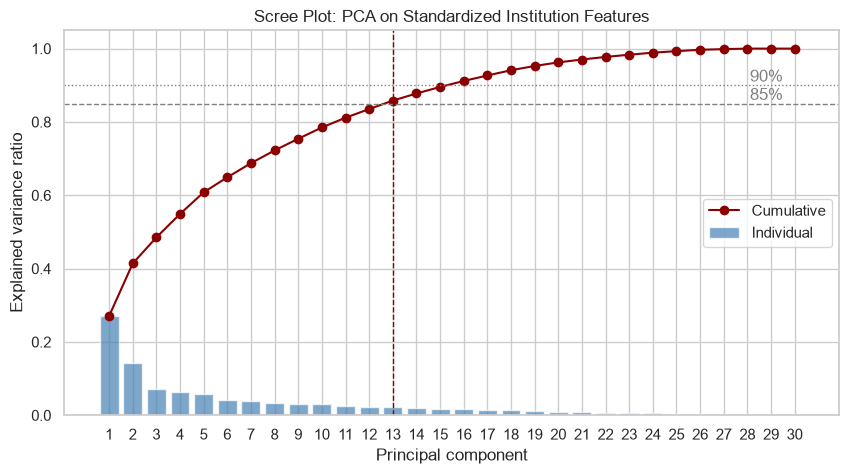

Components for 85% variance: 13 (85.8% explained)
Components for 90% variance: 16
First five components: [0.27  0.143 0.071 0.064 0.059]


In [5]:
pca_full = PCA(random_state=RANDOM_STATE).fit(Z)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

n_components = preprocessor.named_steps["pca"].n_components_
n_components_90 = int(np.searchsorted(cumulative, 0.90) + 1)

fig, ax = plt.subplots(figsize=(10, 5))
pcs = np.arange(1, len(explained) + 1)
ax.bar(pcs, explained, color="steelblue", alpha=0.7, label="Individual")
ax.plot(pcs, cumulative, marker="o", color="darkred", label="Cumulative")
ax.axhline(0.85, color="gray", ls="--", lw=1)
ax.axhline(0.90, color="gray", ls=":", lw=1)
ax.axvline(n_components, color="darkred", ls="--", lw=1)
ax.text(len(pcs) - 0.5, 0.86, "85%", ha="right", color="gray")
ax.text(len(pcs) - 0.5, 0.91, "90%", ha="right", color="gray")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_title("Scree Plot: PCA on Standardized Institution Features")
ax.set_xticks(pcs)
ax.legend(loc="center right")
save_figure(fig, "scree_plot")
plt.show()

print(f"Components for 85% variance: {n_components} "
      f"({cumulative[n_components - 1]:.1%} explained)")
print(f"Components for 90% variance: {n_components_90}")
print("First five components:", np.round(explained[:5], 3))

**13 components** reach the 85% threshold (85.8% of variance), and 16 would be
needed for 90%. The proposal allows 85–90%; the lower end is used because the
three extra components each add about 1.5% of variance, and the scree plot shows
no elbow after the first two components, so the remaining components carry
roughly equal, small amounts of variance. The first component alone explains
27% and the second 14%.

In [6]:
# PCA scores used for all clustering below
P = preprocessor.transform(X_raw)
pca = preprocessor.named_steps["pca"]

loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_names,
    columns=[f"PC{i + 1}" for i in range(n_components)],
)

for pc in ["PC1", "PC2", "PC3", "PC4"]:
    top = loadings[pc].sort_values(key=np.abs, ascending=False).head(6)
    print(f"{pc} ({explained[int(pc[2:]) - 1]:.1%} of variance)")
    print(top.round(3).to_string())
    print()

PC1 (27.0% of variance)
PREDDEG                  0.310
HAS_MASTER               0.302
HAS_BACHELOR             0.296
NUM_CREDENTIAL_LEVELS    0.296
HAS_GRAD_CERT            0.266
HAS_DOCTORAL             0.251

PC2 (14.3% of variance)
NET_PRICE             0.351
PCTFLOAN              0.350
TUITIONFEE_OUT        0.330
PPTUG_EF             -0.316
COST_OF_ATTENDANCE    0.302
UGDS                 -0.300

PC3 (7.1% of variance)
UGDS_WHITE    0.566
UGDS_HISP    -0.389
PCTPELL      -0.296
UGDS_BLACK   -0.274
UGDS_ASIAN   -0.237
NUMBRANCH    -0.208

PC4 (6.4% of variance)
UGDS_ASIAN    0.483
UGDS_2MOR     0.407
UGDS_BLACK   -0.366
UGDS_NHPI     0.334
PCTFLOAN     -0.284
PCTPELL      -0.282



### Interpreting the Leading Components

- **PC1 (27%) — degree level and program breadth.** High scores mean the
  institution mainly awards bachelor's degrees, offers master's, doctoral, and
  graduate-certificate programs, and spans many credential levels. Low scores
  mean narrow, sub-baccalaureate offerings.
- **PC2 (14%) — price and borrowing versus open access.** High scores mean high
  net price, tuition, and cost of attendance with a large share of federal
  borrowers. Low scores mean large enrollments with many part-time students:
  the community-college profile.
- **PC3 (7%) — student racial and ethnic composition.** Mostly White
  enrollments on one side; more Hispanic, Black, and Pell-eligible students and
  more branch campuses on the other.
- **PC4 (6%) — a second composition axis.** Asian, multiracial, and Pacific
  Islander shares versus Black enrollment and Pell and loan shares.

The first two components describe *what kind of education* an institution
provides and *how students pay for it*. The biplot below shows that these two
axes alone already separate much of the sector structure, but with substantial
overlap between public and private nonprofit four-year institutions.

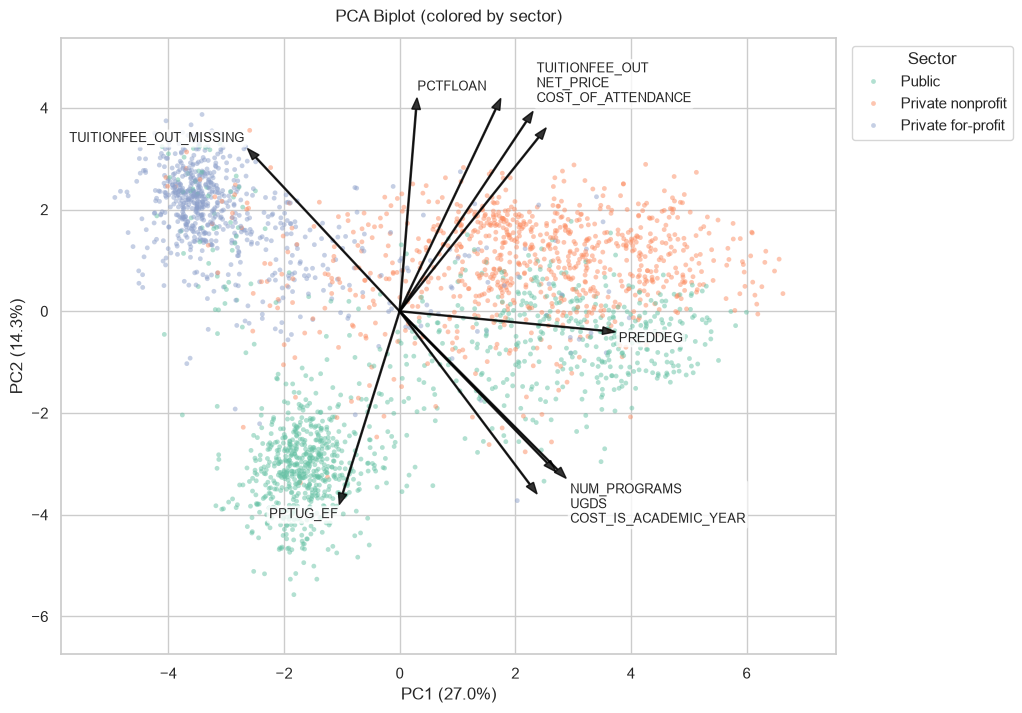

In [7]:
# PCA biplot: institutions on PC1/PC2 with the strongest feature loadings
fig, ax = plt.subplots(figsize=(10, 8))
sns.scatterplot(
    x=P[:, 0], y=P[:, 1], hue=train["SECTOR"], hue_order=SECTOR_ORDER,
    palette=SECTOR_PALETTE, s=12, alpha=0.5, linewidth=0, ax=ax,
)

strength = np.sqrt(loadings["PC1"] ** 2 + loadings["PC2"] ** 2)
top_features = strength.sort_values(ascending=False).head(10).index
scale = np.abs(P[:, :2]).max() * 0.6 / np.abs(loadings.loc[top_features, ["PC1", "PC2"]]).max().max()

# Arrows that point in nearly the same direction share one stacked label,
# so overlapping feature names stay readable.
tips = loadings.loc[top_features, ["PC1", "PC2"]] * scale
groups = []
for feat in top_features:
    x, y = tips.loc[feat]
    ax.arrow(0, 0, x, y, color="black", width=0.02, head_width=0.15, alpha=0.8)
    for group in groups:
        gx, gy = tips.loc[group[0]]
        if np.hypot(x - gx, y - gy) < 1.0:
            group.append(feat)
            break
    else:
        groups.append([feat])

for group in groups:
    longest = np.hypot(tips.loc[group, "PC1"], tips.loc[group, "PC2"]).idxmax()
    x, y = tips.loc[longest]
    ax.text(x * 1.08, y * 1.08, "\n".join(group), fontsize=9,
            ha="left" if x >= 0 else "right", va="bottom" if y >= 0 else "top",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))

ax.set_xlabel(f"PC1 ({explained[0]:.1%})")
ax.set_ylabel(f"PC2 ({explained[1]:.1%})")
ax.set_title("PCA Biplot (colored by sector)", pad=12)
ax.margins(x=0.08, y=0.12)
ax.legend(title="Sector", loc="upper left", bbox_to_anchor=(1.01, 1))
save_figure(fig, "pca_biplot")
plt.show()

## 4. Compare Clustering Methods Across k

Three clustering methods are fit on the retained PCA scores for k = 3 to 12:

- **k-means:** spherical clusters around centroids.
- **Gaussian mixture (full covariance):** elliptical clusters with soft
  membership.
- **Ward agglomerative clustering:** hierarchical merges that minimize the
  increase in within-cluster variance.

For each solution we record silhouette (higher is better), Davies–Bouldin
(lower is better), the smallest cluster size, and ARI against sector labels.
Inertia is recorded for k-means (elbow method) and BIC for Gaussian mixtures.

In [8]:
def fit_labels(method, k, data, seed=RANDOM_STATE):
    # Fit one clustering method and return (labels, fitted model)
    if method == "k-means":
        model = KMeans(n_clusters=k, n_init=20, random_state=seed).fit(data)
        return model.labels_, model
    if method == "GMM":
        model = GaussianMixture(n_components=k, covariance_type="full",
                                n_init=3, random_state=seed).fit(data)
        return model.predict(data), model
    if method == "Ward":
        model = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(data)
        return model.labels_, model
    raise ValueError(method)


METHODS = ["k-means", "GMM", "Ward"]
sector = train["CONTROL"].to_numpy()

rows = []
for k in K_RANGE:
    for method in METHODS:
        labels, model = fit_labels(method, k, P)
        rows.append({
            "method": method,
            "k": k,
            "silhouette": silhouette_score(P, labels),
            "davies_bouldin": davies_bouldin_score(P, labels),
            "min_cluster_size": np.bincount(labels).min(),
            "ari_vs_sector": adjusted_rand_score(sector, labels),
            "inertia": model.inertia_ if method == "k-means" else np.nan,
            "bic": model.bic(P) if method == "GMM" else np.nan,
        })

sweep = pd.DataFrame(rows)
sweep.to_csv(RESULTS_DIR / "clustering_sweep.csv", index=False)

for metric in ["silhouette", "davies_bouldin", "min_cluster_size", "ari_vs_sector"]:
    print(metric)
    display(sweep.pivot(index="k", columns="method", values=metric)[METHODS].round(3))

silhouette


method,k-means,GMM,Ward
k,,,
3,0.296,0.214,0.281
4,0.283,0.240,0.256
5,0.286,0.188,0.248
6,0.284,0.199,0.254
7,0.246,0.205,0.259
8,0.282,0.153,0.260
9,0.234,0.131,0.259
10,0.277,0.065,0.265
11,0.267,0.129,0.260


davies_bouldin


method,k-means,GMM,Ward
k,,,
3,1.232,2.940,1.322
4,1.531,2.523,1.709
5,1.380,2.323,1.928
6,1.490,2.459,1.759
7,1.641,2.358,1.681
8,1.468,2.666,1.589
9,1.676,2.701,1.677
10,1.369,2.683,1.628
11,1.391,2.295,1.562


min_cluster_size


method,k-means,GMM,Ward
k,,,
3,687,426,614
4,609,444,577
5,11,435,398
6,11,227,12
7,11,10,12
8,10,151,12
9,10,131,12
10,3,87,12
11,3,3,12


ari_vs_sector


method,k-means,GMM,Ward
k,,,
3,0.422,0.205,0.348
4,0.384,0.322,0.323
5,0.381,0.269,0.340
6,0.369,0.276,0.337
7,0.315,0.290,0.341
8,0.345,0.250,0.342
9,0.286,0.247,0.333
10,0.310,0.184,0.320
11,0.293,0.217,0.321


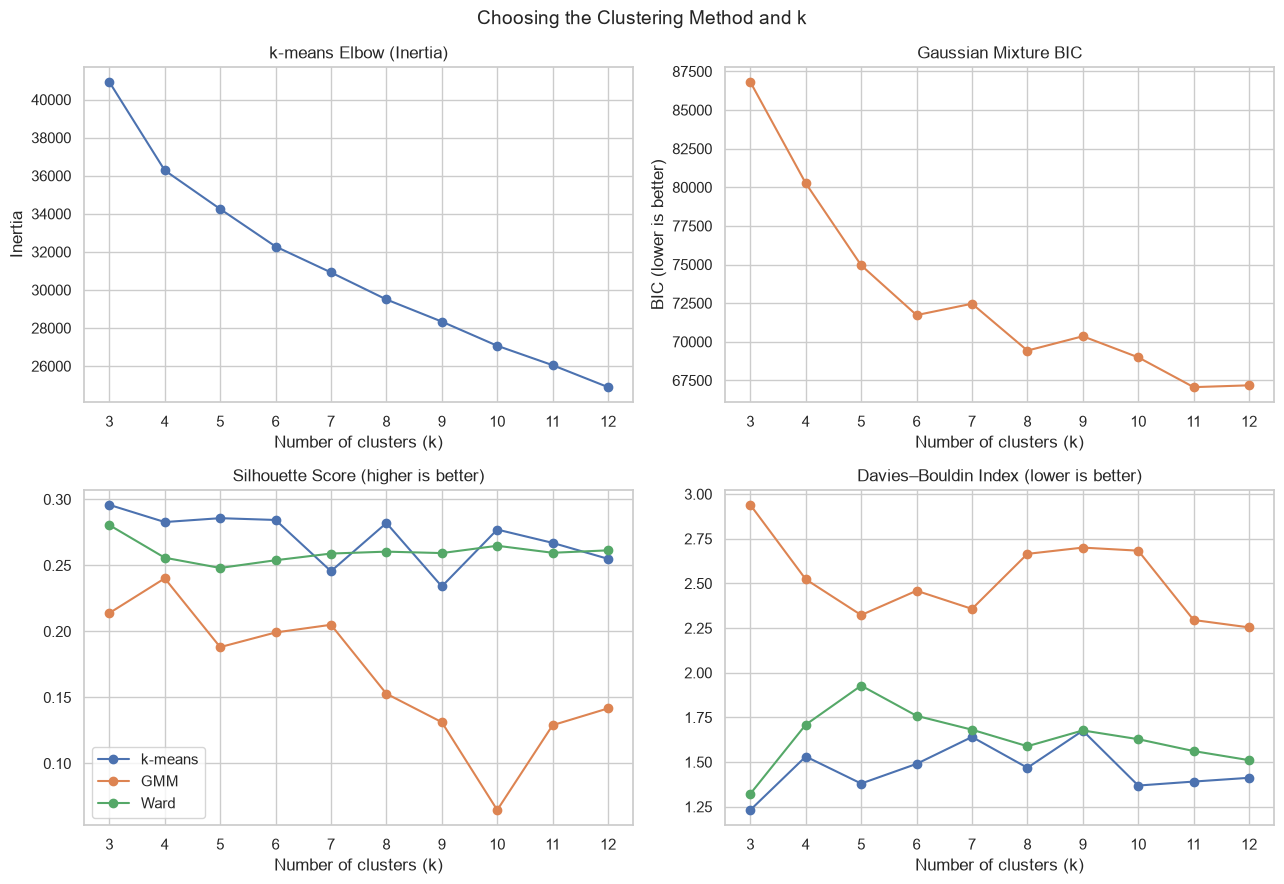

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
method_colors = dict(zip(METHODS, sns.color_palette("deep", 3)))

km = sweep[sweep["method"] == "k-means"]
axes[0, 0].plot(km["k"], km["inertia"], marker="o", color=method_colors["k-means"])
axes[0, 0].set_title("k-means Elbow (Inertia)")
axes[0, 0].set_ylabel("Inertia")

gm = sweep[sweep["method"] == "GMM"]
axes[0, 1].plot(gm["k"], gm["bic"], marker="o", color=method_colors["GMM"])
axes[0, 1].set_title("Gaussian Mixture BIC")
axes[0, 1].set_ylabel("BIC (lower is better)")

for method in METHODS:
    sub = sweep[sweep["method"] == method]
    axes[1, 0].plot(sub["k"], sub["silhouette"], marker="o", label=method, color=method_colors[method])
    axes[1, 1].plot(sub["k"], sub["davies_bouldin"], marker="o", label=method, color=method_colors[method])
axes[1, 0].set_title("Silhouette Score (higher is better)")
axes[1, 1].set_title("Davies–Bouldin Index (lower is better)")
axes[1, 0].legend()

for ax in axes.flat:
    ax.set_xlabel("Number of clusters (k)")
    ax.set_xticks(list(K_RANGE))

fig.suptitle("Choosing the Clustering Method and k", fontsize=14)
fig.tight_layout()
save_figure(fig, "clustering_metrics")
plt.show()

### What the Sweep Shows

- **k-means is the strongest method on the internal metrics.** It has the
  highest silhouette at most values of k and the lowest Davies–Bouldin index
  at every k.
  Ward is close behind; Gaussian mixtures are clearly worse (silhouette 0.07–0.24,
  Davies–Bouldin above 2.2).
- **There is no sharp elbow.** k-means inertia falls smoothly, and the GMM BIC
  generally keeps decreasing until it levels off at k = 11–12. A BIC that keeps
  favoring more components is common with full-covariance mixtures on
  continuous data and is not by itself evidence for 11 natural groups.
- **Larger k produces tiny clusters.** From k = 5 (k-means) and k = 6 (Ward),
  a cluster of only 11–12 institutions splits off, and at k ≥ 10 k-means
  produces clusters as small as 3 institutions. Inspection shows these are
  Hawaii- and Pacific-Islander-serving institutions with very high
  `UGDS_NHPI` and `UGDS_2MOR` shares. This is a real but very small group;
  a cluster of about 0.4% of institutions is too small to be a useful
  institution type or a reliable model feature.
- **Silhouette values of 0.25–0.30 indicate moderate structure.** Institutions
  form recognizable groups, but the boundaries between groups are not sharp.

Silhouette and Davies–Bouldin both favor k = 3 for k-means, with k = 4–6 only
slightly behind. Stability is used to narrow the choice.

## 5. Bootstrap Stability

Following the timeline, unstable clusters are not treated as findings. For each
method and k from 3 to 8, the clustering is refit on 30 bootstrap resamples of
the training institutions. Each bootstrap model then assigns labels to the full
training set, and those labels are compared with the reference solution using
ARI. Values near 1 mean the same clusters reappear when the sample changes.

k-means and Gaussian mixtures assign new points with their own `predict`
method. Ward clustering has no `predict`, so each institution is assigned to
the nearest bootstrap Ward cluster centroid.

In [10]:
N_BOOTSTRAP = 30
STABILITY_K = range(3, 9)


def assign_with_model(method, model, labels_fit, data_fit, data_all):
    # Assign every institution to a cluster using a model fit on a resample
    if method in ("k-means", "GMM"):
        return model.predict(data_all)
    centroids = np.vstack([data_fit[labels_fit == c].mean(axis=0)
                           for c in np.unique(labels_fit)])
    dists = np.linalg.norm(data_all[:, None, :] - centroids[None, :, :], axis=2)
    return dists.argmin(axis=1)


rng = np.random.default_rng(RANDOM_STATE)
boot_indices = [rng.integers(0, len(P), len(P)) for _ in range(N_BOOTSTRAP)]

stability_rows = []
for method in METHODS:
    for k in STABILITY_K:
        reference, _ = fit_labels(method, k, P)
        for b, idx in enumerate(boot_indices):
            labels_b, model_b = fit_labels(method, k, P[idx], seed=b)
            assigned = assign_with_model(method, model_b, labels_b, P[idx], P)
            stability_rows.append({
                "method": method, "k": k, "bootstrap": b,
                "ari": adjusted_rand_score(reference, assigned),
            })

stability = pd.DataFrame(stability_rows)
stability.to_csv(RESULTS_DIR / "bootstrap_stability.csv", index=False)

stability_summary = (
    stability.groupby(["method", "k"])["ari"].agg(["mean", "std"]).round(3)
    .unstack("method").swaplevel(axis=1).sort_index(axis=1)
)
display(stability_summary[METHODS])

method k-means           GMM          Ward       
          mean    std   mean    std   mean    std
k                                                
3        0.989  0.006  0.534  0.136  0.800  0.010
4        0.965  0.055  0.702  0.095  0.737  0.032
5        0.921  0.067  0.602  0.103  0.731  0.028
6        0.909  0.043  0.662  0.104  0.751  0.024
7        0.786  0.066  0.589  0.075  0.753  0.025
8        0.816  0.063  0.605  0.054  0.752  0.031

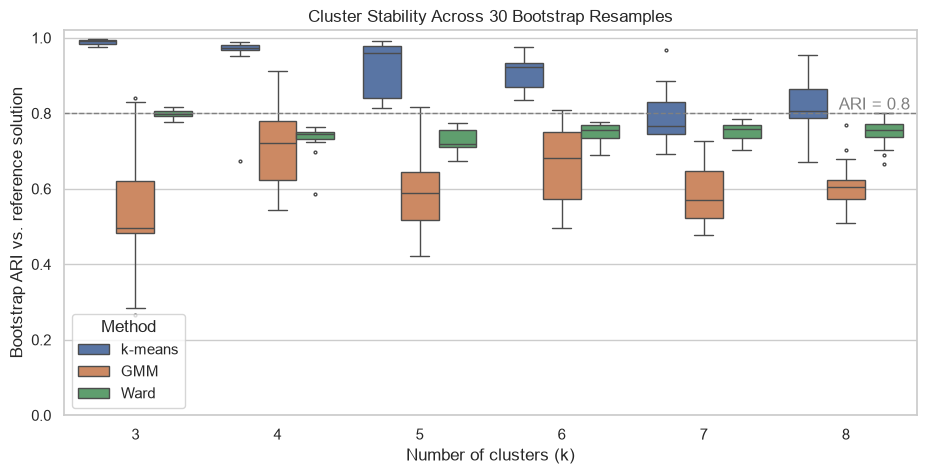

In [11]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=stability, x="k", y="ari", hue="method", hue_order=METHODS,
            palette=method_colors, ax=ax, fliersize=2)
ax.axhline(0.8, color="gray", ls="--", lw=1)
ax.text(5.45, 0.81, "ARI = 0.8", color="gray", ha="right")
ax.set_ylim(0, 1.02)
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Bootstrap ARI vs. reference solution")
ax.set_title(f"Cluster Stability Across {N_BOOTSTRAP} Bootstrap Resamples")
ax.legend(title="Method", loc="lower left")
save_figure(fig, "bootstrap_stability")
plt.show()

## 6. Select the Method and k

The proposal and timeline call for choosing the method and k from the metrics
together with interpretability. Stability is now added as a further filter.

**Stability rules out Gaussian mixtures and favors k-means.** k-means is highly
stable at k = 3 and 4 (mean bootstrap ARI 0.99 and 0.97) and remains above 0.9
through k = 6 before falling below 0.82. Ward stays around 0.73–0.80 and GMM
around 0.53–0.70, meaning their clusters change noticeably when the sample
changes.

**k-means with k = 4 is selected:**

- **Stable:** bootstrap ARI 0.97.
- **Good internal metrics:** silhouette 0.283, close to the best value of 0.296
  at k = 3.
- **Balanced:** the smallest cluster has 609 institutions; no tiny clusters.
- **Interpretable:** k = 3 puts all 1,203 four-year institutions into a single
  cluster. k = 4 splits them into broad doctoral universities and
  smaller four-year colleges, two groups with clearly different debt burdens
  (Section 9). k = 5 and 6 only add the 11-institution Pacific Islander
  cluster.

Debt burden was not used to choose k; it is only used afterward to describe
the clusters.

In [12]:
SELECTED_METHOD = "k-means"
SELECTED_K = 4

candidates = sweep[sweep["k"].isin(STABILITY_K)].merge(
    stability.groupby(["method", "k"])["ari"].mean().rename("bootstrap_ari").reset_index(),
    on=["method", "k"],
)
print("Candidate solutions with stability (k = 3 to 8):")
display(
    candidates[["method", "k", "silhouette", "davies_bouldin", "bootstrap_ari",
                "min_cluster_size", "ari_vs_sector"]]
    .sort_values(["method", "k"]).round(3).set_index(["method", "k"])
)

cluster_labels, final_model = fit_labels(SELECTED_METHOD, SELECTED_K, P)
train["cluster"] = cluster_labels

print(f"Selected: {SELECTED_METHOD}, k = {SELECTED_K}")
print("Cluster sizes:", np.bincount(cluster_labels).tolist())

Candidate solutions with stability (k = 3 to 8):


silhouette  davies_bouldin  bootstrap_ari  min_cluster_size  \
method  k                                                                
GMM     3       0.214           2.940          0.534               426   
        4       0.240           2.523          0.702               444   
        5       0.188           2.323          0.602               435   
        6       0.199           2.459          0.662               227   
        7       0.205           2.358          0.589                10   
        8       0.153           2.666          0.605               151   
Ward    3       0.281           1.322          0.800               614   
        4       0.256           1.709          0.737               577   
        5       0.248           1.928          0.731               398   
        6       0.254           1.759          0.751                12   
        7       0.259           1.681          0.753                12   
        8       0.260           1.589          0.752                12   
k-means 3       0.296           1.232          0.989               687   
        4       0.283           1.531          0.965               609   
        5       0.286           1.380          0.921                11   
        6       0.284           1.490          0.909                11   
        7       0.246           1.641          0.786                11   
        8       0.282           1.468          0.816                10   

           ari_vs_sector  
method  k                 
GMM     3          0.205  
        4          0.322  
        5          0.269  
        6          0.276  
        7          0.290  
        8          0.250  
Ward    3          0.348  
        4          0.323  
        5          0.340  
        6          0.337  
        7          0.341  
        8          0.342  
k-means 3          0.422  
        4          0.384  
        5          0.381  
        6          0.369  
        7          0.315  
        8          0.345

Selected: k-means, k = 4
Cluster sizes: [685, 690, 609, 652]


## 7. Do the Clusters Reproduce Sector?

This is the headline unsupervised result. ARI compares the cluster labels with
the three sector labels: 0 means agreement no better than chance and 1 means
the clusters are exactly the sectors. Normalized mutual information (NMI) is
reported as a second agreement measure.

In [13]:
ari_sector = adjusted_rand_score(train["CONTROL"], train["cluster"])
nmi_sector = normalized_mutual_info_score(train["CONTROL"], train["cluster"])
print(f"ARI (clusters vs. sector): {ari_sector:.3f}")
print(f"NMI (clusters vs. sector): {nmi_sector:.3f}")

# Degree level is the other conventional way to group institutions, so the
# clusters are also compared with it and with the sector x degree combination.
train["DEGREE"] = train["PREDDEG"].map(PREDDEG_LABELS)
train["SECTOR_X_DEGREE"] = train["SECTOR"] + " / " + train["DEGREE"]
for name in ["DEGREE", "SECTOR_X_DEGREE"]:
    print(f"ARI (clusters vs. {name.lower()}): "
          f"{adjusted_rand_score(train[name], train['cluster']):.3f}")

crosstab = pd.crosstab(train["cluster"], train["SECTOR"])[SECTOR_ORDER]
crosstab_pct = crosstab.div(crosstab.sum(axis=1), axis=0)
print("\nInstitutions per cluster and sector:")
display(crosstab.assign(Total=crosstab.sum(axis=1)))

ARI (clusters vs. sector): 0.384
NMI (clusters vs. sector): 0.407
ARI (clusters vs. degree): 0.495
ARI (clusters vs. sector_x_degree): 0.488

Institutions per cluster and sector:


SECTOR,Public,Private nonprofit,Private for-profit,Total
cluster,,,,
0,59,40,586,685
1,141,481,68,690
2,283,311,15,609
3,623,20,9,652


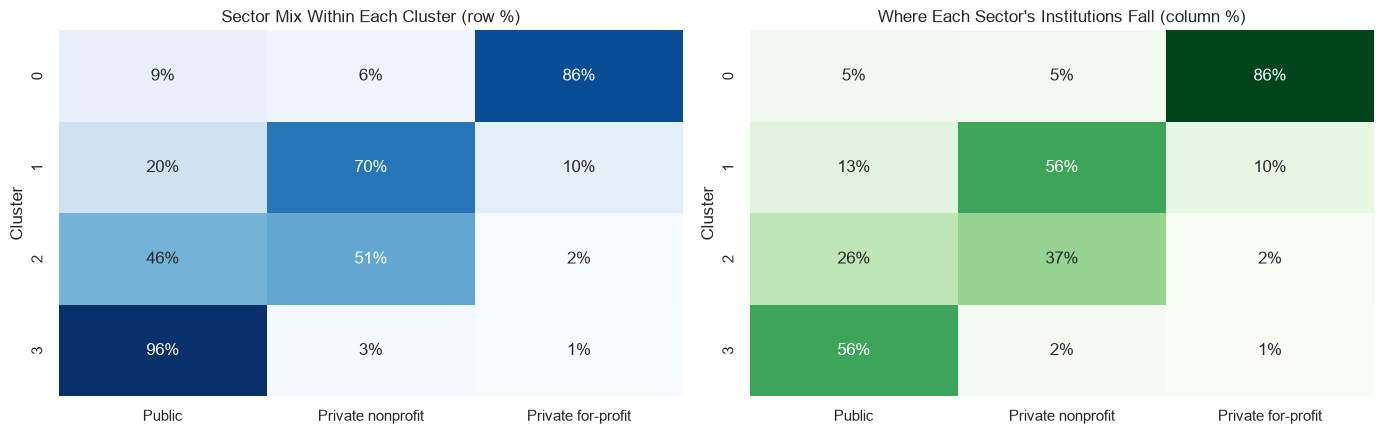

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.heatmap(crosstab_pct, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Sector Mix Within Each Cluster (row %)")
axes[0].set_xlabel("")
axes[0].set_ylabel("Cluster")

sector_share = crosstab.div(crosstab.sum(axis=0), axis=1)
sns.heatmap(sector_share, annot=True, fmt=".0%", cmap="Greens", cbar=False, ax=axes[1])
axes[1].set_title("Where Each Sector's Institutions Fall (column %)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Cluster")

fig.tight_layout()
save_figure(fig, "cluster_vs_sector")
plt.show()

### Clusters Partly Reproduce Sector, But Not Entirely

**ARI against sector is 0.38 (NMI 0.41): moderate agreement.** The clusters are
clearly related to sector but are not a relabeling of it:

- **Two clusters are close to a single sector.** The certificate cluster is
  86% for-profit and the community-college cluster is 96% public.
- **Public and private nonprofit four-year institutions are mixed together.**
  Both four-year clusters contain large numbers of both sectors, and the split
  between them is by institutional scope (size, graduate and doctoral
  programs), not by control.
- **Public institutions are spread across all four clusters**, from 59
  certificate-focused technical schools to 283 doctoral universities.

The clusters agree somewhat more with predominant degree level (ARI ≈ 0.50)
than with sector. This matches the PCA: the main axis of variation is degree
level and program breadth, so the clusters are best understood as a
*combination* of degree level, scope, price, and sector rather than as a
replacement for them.

## 8. Cluster Profiles

Each cluster is described in two ways:

1. A heatmap of the mean standardized value of each clustering feature, which
   shows what distinguishes each cluster from the average institution.
2. A table of typical raw values (medians and shares) that are easier to read.

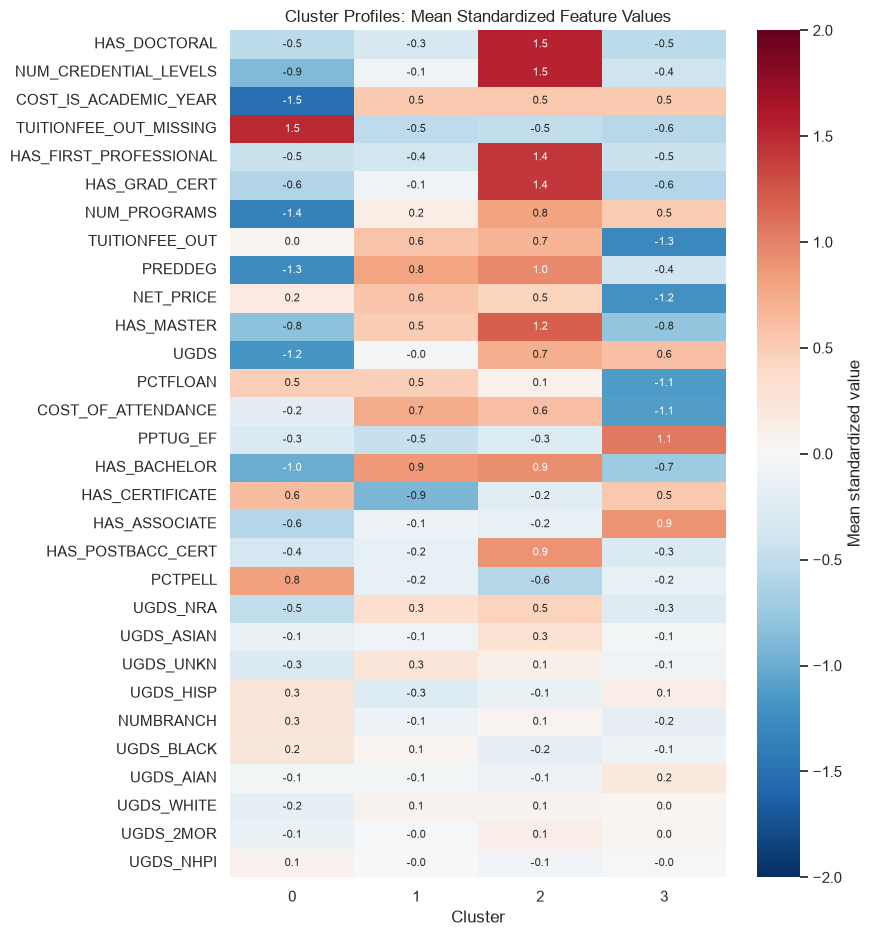

In [15]:
profile_z = Z_df.groupby(train["cluster"]).mean().T

# Order features so related variables sit together
profile_z = profile_z.loc[profile_z.abs().max(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8, 11))
sns.heatmap(profile_z, cmap="RdBu_r", center=0, vmin=-2, vmax=2,
            annot=True, fmt=".1f", annot_kws={"size": 8},
            cbar_kws={"label": "Mean standardized value"}, ax=ax)
ax.set_xlabel("Cluster")
ax.set_ylabel("")
ax.set_title("Cluster Profiles: Mean Standardized Feature Values")
save_figure(fig, "cluster_profile_heatmap")
plt.show()

In [16]:
def share(value):
    return lambda s: (s == value).mean()


profile_table = train.groupby("cluster").agg(
    institutions=("OPEID6", "size"),
    pct_public=("CONTROL", share(1)),
    pct_nonprofit=("CONTROL", share(2)),
    pct_for_profit=("CONTROL", share(3)),
    median_enrollment=("UGDS", "median"),
    median_cost_of_attendance=("COST_OF_ATTENDANCE", "median"),
    median_net_price=("NET_PRICE", "median"),
    median_pct_pell=("PCTPELL", "median"),
    median_pct_fed_loan=("PCTFLOAN", "median"),
    median_pct_part_time=("PPTUG_EF", "median"),
    median_pct_white=("UGDS_WHITE", "median"),
    median_pct_black=("UGDS_BLACK", "median"),
    median_pct_hispanic=("UGDS_HISP", "median"),
    median_programs=("NUM_PROGRAMS", "median"),
    pct_offer_bachelor=("HAS_BACHELOR", "mean"),
    pct_offer_graduate=("HAS_MASTER", "mean"),
    median_burden=("debt_burden", "median"),
)
profile_table["most_common_degree"] = (
    train.groupby("cluster")["PREDDEG"].agg(lambda s: s.mode()[0]).map(PREDDEG_LABELS)
)
profile_table.T.to_csv(RESULTS_DIR / "cluster_profiles.csv")

def format_profile_value(column, value):
    if column == "most_common_degree":
        return value
    if column == "median_burden":
        return f"{value:.2f}"
    if "pct" in column:
        return f"{value:.0%}"
    return f"{value:,.0f}"


display(profile_table.apply(
    lambda col: col.map(lambda v: format_profile_value(col.name, v))
).T)

cluster,0,1,2,3
institutions,685,690,609,652
pct_public,9%,20%,46%,96%
pct_nonprofit,6%,70%,51%,3%
pct_for_profit,86%,10%,2%,1%
median_enrollment,182,"1,440","5,398","3,856"
median_cost_of_attendance,"18,837","32,324","27,450","12,134"
median_net_price,"15,290","19,205","17,657","7,221"
median_pct_pell,61%,41%,34%,41%
median_pct_fed_loan,64%,66%,56%,23%
median_pct_part_time,0%,7%,12%,50%


### Describing the Clusters

The heatmap and table give a clear description of each cluster:

| Cluster | Description | Distinguishing features |
|---|---|---|
| **Certificate schools** | Very small, mostly for-profit (86%), single-program certificate schools | Median 182 undergraduates and 1 program; highest Pell share (61%); program-year cost reporting; tuition rarely reported |
| **Four-year teaching colleges** | Small and mid-sized bachelor's colleges, mostly private nonprofit (70%) with some regional publics | Median 1,440 undergraduates; highest cost of attendance ($32k) and net price ($19k); 66% offer master's but few offer doctorates |
| **Doctoral universities** | Large universities, split almost evenly between public (46%) and private nonprofit (51%) | Median 5,400 undergraduates and 57 programs; all offer bachelor's and master's, 87% doctoral; lowest Pell share (34%) |
| **Community colleges** | Public two-year colleges (96% public) | Half of students part-time; lowest cost ($12k) and net price ($7k); only 23% take federal loans |

Racial and ethnic composition differs little between clusters (all within
±0.3 standard deviations), so the clusters are driven by institutional scope,
price, and enrollment patterns rather than student demographics.

The names below are assigned from these characteristics rather than from fixed
cluster numbers, so they stay correct if the cluster numbering changes on a
rerun.

In [17]:
# Name each cluster by its defining characteristics
cluster_means = train.groupby("cluster")[
    ["HAS_DOCTORAL", "PPTUG_EF", "NUM_PROGRAMS"]
].mean()

doctoral = cluster_means["HAS_DOCTORAL"].idxmax()
community = cluster_means["PPTUG_EF"].idxmax()
certificate = cluster_means["NUM_PROGRAMS"].idxmin()
remaining = set(cluster_means.index) - {doctoral, community, certificate}
assert len(remaining) == 1, "Cluster naming rules did not identify four distinct clusters"

CLUSTER_NAMES = {
    certificate: "Certificate schools",
    remaining.pop(): "Four-year teaching colleges",
    doctoral: "Doctoral universities",
    community: "Community colleges",
}
CLUSTER_NAMES = dict(sorted(CLUSTER_NAMES.items()))
train["cluster_name"] = train["cluster"].map(CLUSTER_NAMES)

display(pd.DataFrame({
    "cluster_name": pd.Series(CLUSTER_NAMES),
    "institutions": train["cluster"].value_counts().sort_index(),
}).rename_axis("cluster"))

,cluster_name,institutions
cluster,,
0,Certificate schools,685
1,Four-year teaching colleges,690
2,Doctoral universities,609
3,Community colleges,652


## 9. Debt Burden Across Clusters

Debt burden was not used to form the clusters. Comparing it across clusters
therefore tests whether the structure found in pre-outcome characteristics is
related to later outcomes.

The Kruskal–Wallis test checks whether burden distributions differ across
groups. Eta-squared (η²) measures the share of burden variance explained by
group membership, which allows the clusters to be compared directly with the
sector labels.

,groups,kruskal_H,p_value,eta_squared
grouping,,,,
Clusters,4,698.5,4.44e-151,0.236
Sector,3,350.4,8.25e-77,0.117


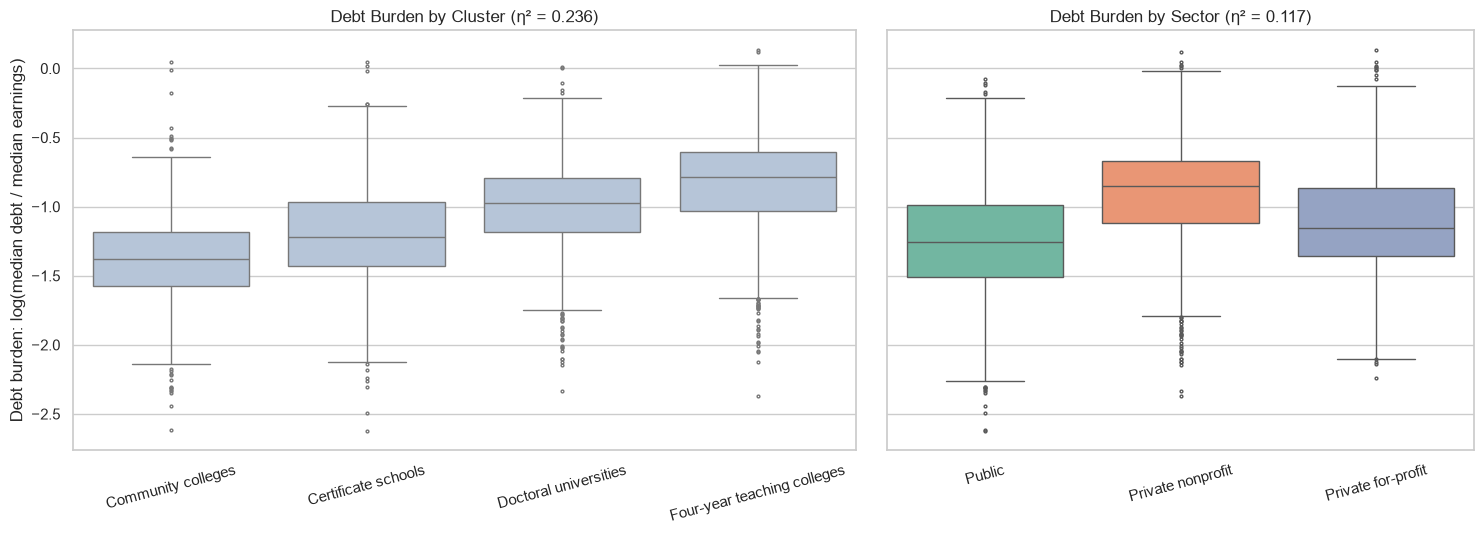

In [18]:
def eta_squared(values, groups):
    group_means = values.groupby(groups).transform("mean")
    return ((group_means - values.mean()) ** 2).sum() / ((values - values.mean()) ** 2).sum()


burden = train["debt_burden"]

comparison = []
for name, groups in [("Clusters", train["cluster_name"]), ("Sector", train["SECTOR"])]:
    h, p = stats.kruskal(*[burden[groups == g] for g in groups.unique()])
    comparison.append({"grouping": name, "groups": groups.nunique(),
                       "kruskal_H": h, "p_value": p, "eta_squared": eta_squared(burden, groups)})
comparison = pd.DataFrame(comparison).set_index("grouping")
display(comparison.style.format({"kruskal_H": "{:.1f}", "p_value": "{:.2e}", "eta_squared": "{:.3f}"}))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [SELECTED_K, 3]}, sharey=True)
cluster_order = (train.groupby("cluster_name")["debt_burden"].median().sort_values().index)
sns.boxplot(data=train, x="cluster_name", y="debt_burden", order=cluster_order,
            color="lightsteelblue", fliersize=2, ax=axes[0])
axes[0].set_title(f"Debt Burden by Cluster (η² = {comparison.loc['Clusters', 'eta_squared']:.3f})")
axes[0].set_xlabel("")
axes[0].set_ylabel("Debt burden: log(median debt / median earnings)")
axes[0].tick_params(axis="x", rotation=15)

sns.boxplot(data=train, x="SECTOR", y="debt_burden", order=SECTOR_ORDER,
            hue="SECTOR", palette=SECTOR_PALETTE, legend=False, fliersize=2, ax=axes[1])
axes[1].set_title(f"Debt Burden by Sector (η² = {comparison.loc['Sector', 'eta_squared']:.3f})")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=15)

fig.tight_layout()
save_figure(fig, "burden_boxplots")
plt.show()

### Do Clusters Separate Burden Within a Sector?

If the clusters only re-labeled sectors, burden would not vary across clusters
once sector is held fixed. The table below shows median burden for each
cluster × sector combination with at least 20 institutions.

The second table compares how much burden variance different groupings explain
(in-sample R² from a regression on group indicators). Besides sector, the
clusters are compared with predominant degree level and with the full
sector × degree combination, because degree level is the other conventional
way to group institutions and a fair benchmark for a four-group typology.
These are descriptive, in-sample numbers; the out-of-sample test of whether
cluster features improve prediction is done in `04_integration.ipynb`.

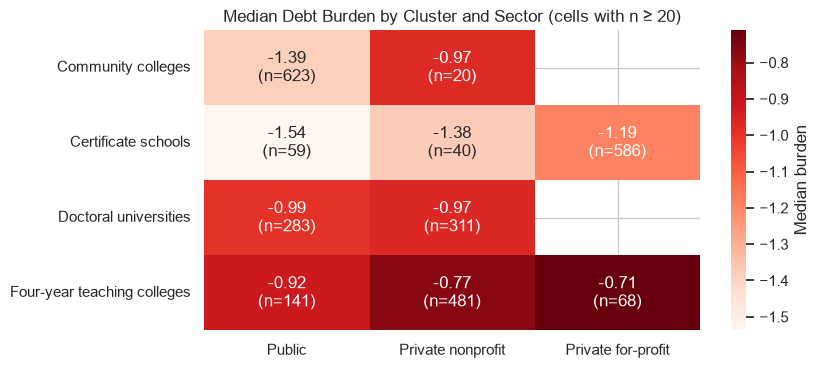

,groups,in_sample_r2
Sector,3,0.117
Predominant degree,4,0.167
Clusters,4,0.236
Sector + degree,10,0.248
Sector x degree,10,0.258
Sector + clusters,12,0.262
Sector x degree + clusters,30,0.283


In [19]:
cell = train.groupby(["cluster_name", "SECTOR"])["debt_burden"].agg(["median", "size"])
median_table = cell["median"].where(cell["size"] >= 20).unstack()[SECTOR_ORDER].loc[cluster_order]
count_table = cell["size"].unstack()[SECTOR_ORDER].loc[cluster_order].fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(8, 0.6 * SELECTED_K + 1.5))
annot = median_table.round(2).astype(str) + "\n(n=" + count_table.astype(str) + ")"
annot = annot.where(median_table.notna(), "n=" + count_table.astype(str))
sns.heatmap(median_table, annot=annot, fmt="", cmap="Reds", cbar_kws={"label": "Median burden"}, ax=ax)
ax.set_title("Median Debt Burden by Cluster and Sector (cells with n ≥ 20)")
ax.set_xlabel("")
ax.set_ylabel("")
save_figure(fig, "burden_cluster_by_sector")
plt.show()


def r_squared(groups_df):
    design = pd.get_dummies(groups_df.astype(str), drop_first=True).astype(float)
    design.insert(0, "const", 1.0)
    coef, *_ = np.linalg.lstsq(design.to_numpy(), burden.to_numpy(), rcond=None)
    resid = burden.to_numpy() - design.to_numpy() @ coef
    return 1 - (resid ** 2).sum() / ((burden - burden.mean()) ** 2).sum()


groupings = {
    "Sector": ["SECTOR"],
    "Predominant degree": ["DEGREE"],
    "Clusters": ["cluster_name"],
    "Sector + degree": ["SECTOR", "DEGREE"],
    "Sector x degree": ["SECTOR_X_DEGREE"],
    "Sector + clusters": ["SECTOR", "cluster_name"],
    "Sector x degree + clusters": ["SECTOR_X_DEGREE", "cluster_name"],
}
r2_table = pd.DataFrame({
    "groups": {name: train[cols].drop_duplicates().shape[0] for name, cols in groupings.items()},
    "in_sample_r2": {name: r_squared(train[cols]) for name, cols in groupings.items()},
})
r2_table.to_csv(RESULTS_DIR / "burden_r2_by_grouping.csv")
display(r2_table.style.format({"in_sample_r2": "{:.3f}"}))

### Clusters Differ Strongly in Burden

**The clusters explain twice as much burden variance as sector.**
Cluster membership explains 23.6% of the variance in debt burden, compared with
11.7% for sector (Kruskal–Wallis p < 10⁻¹⁵⁰ for clusters and p < 10⁻⁷⁶ for
sector). The ordering is intuitive:

- **Community colleges** have the lowest burden: low prices and few borrowers.
- **Certificate schools** come next. Their programs are short, so debt is
  modest, but so are earnings.
- **Doctoral universities** are in the middle.
- **Four-year teaching colleges** have the highest burden: the highest prices
  with moderate earnings.

**The clusters separate burden within sectors.**

- **Public institutions:** median burden ranges from −1.54 in certificate
  schools and −1.39 in community colleges to about −0.95 in four-year
  institutions. Clusters explain 29% of burden variance within the public
  sector.
- **For-profit institutions:** the 68 for-profit institutions in the
  four-year-college cluster have a median burden of −0.71, much heavier than the
  586 for-profit certificate schools at −1.19. Sector alone treats these as one
  group.
- **Private nonprofits:** four-year teaching colleges (−0.77) carry heavier
  burden than doctoral universities (−0.97).

**The fair benchmark is degree level, not just sector.** The four clusters
explain more burden variance than predominant degree level alone (16.7%) and
nearly as much as all ten sector × degree combinations (25.8%). Adding clusters
to sector × degree raises R² only modestly, from 0.258 to 0.283. The clusters
are therefore a compact summary that captures most of what sector and degree
level together say about burden, plus a small amount of additional
information. Whether that additional information improves *out-of-sample*
prediction is the question for `04_integration.ipynb`.

## 10. Two-Dimensional Projection (UMAP)

UMAP projects the retained PCA scores into two dimensions for visualization
only; the clusters were formed in the full PCA space. The same projection is
colored by cluster and by sector, so the two groupings can be compared
directly.

C:\Users\domin\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


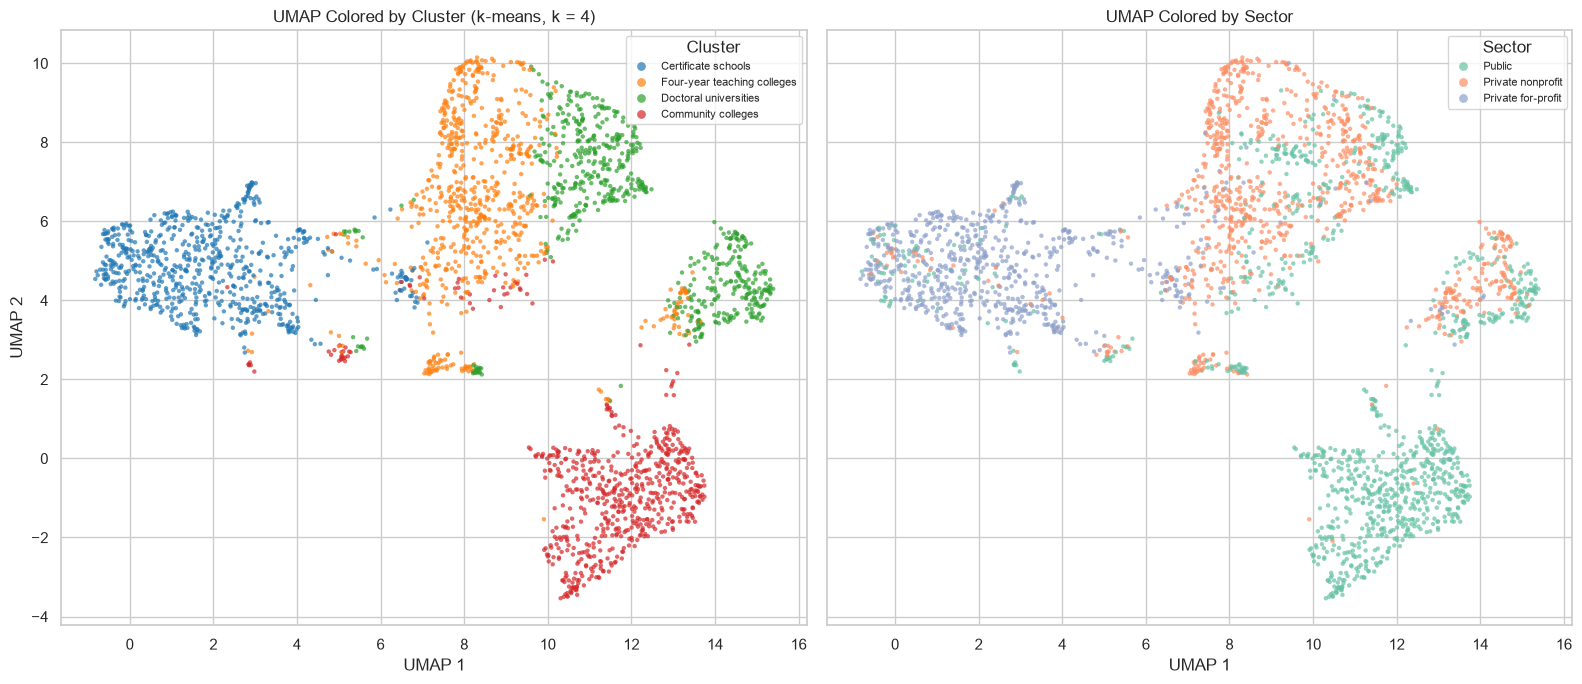

In [20]:
embedding = umap.UMAP(n_neighbors=30, min_dist=0.3, random_state=RANDOM_STATE).fit_transform(P)
train["umap_1"], train["umap_2"] = embedding[:, 0], embedding[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)
sns.scatterplot(data=train, x="umap_1", y="umap_2", hue="cluster_name",
                hue_order=list(CLUSTER_NAMES.values()), palette="tab10",
                s=10, alpha=0.7, linewidth=0, ax=axes[0])
axes[0].set_title(f"UMAP Colored by Cluster ({SELECTED_METHOD}, k = {SELECTED_K})")
axes[0].legend(title="Cluster", fontsize=8, markerscale=2, loc="best")

sns.scatterplot(data=train, x="umap_1", y="umap_2", hue="SECTOR",
                hue_order=SECTOR_ORDER, palette=SECTOR_PALETTE,
                s=10, alpha=0.7, linewidth=0, ax=axes[1])
axes[1].set_title("UMAP Colored by Sector")
axes[1].legend(title="Sector", fontsize=8, markerscale=2, loc="best")

for ax in axes:
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")

fig.tight_layout()
save_figure(fig, "umap_cluster_vs_sector")
plt.show()

The UMAP projection supports the cluster solution:

- **Community colleges** and **certificate schools** form two distinct regions,
  matching their near-single-sector composition.
- **The two four-year clusters** occupy a large connected region in which public
  and private nonprofit institutions are interleaved. The cluster coloring
  divides this region by institutional scope, while the sector coloring shows
  no clean public/nonprofit boundary. This is the clearest visual evidence that
  the typology cuts across sector labels.
- A small number of for-profit and public institutions sit inside regions
  dominated by other sectors, which matches the cross-sector cells in the
  sector table.

## 11. Cluster-Derived Features for Integration

The integration notebook adds two kinds of cluster information to the best
supervised model:

- **Cluster membership:** one-hot indicators `cluster_0` … `cluster_{k-1}`.
- **Centroid distances:** the distance from each institution to every cluster
  centroid in PCA space, which captures how typical an institution is of each
  type.

`make_cluster_feature_pipeline` in `src/unsupervised.py` bundles the full
filter → impute → scale → PCA → k-means pipeline with the selected settings.
**It must be refit inside each training fold in `04_integration.ipynb`.** The
features below are fit on the full training set and are saved only for
reference and visualization; using them in cross-validation would leak
information from validation folds into the features.

The cell below confirms that the packaged pipeline reproduces the clusters
selected in this notebook.

In [21]:
cluster_pipeline = make_cluster_feature_pipeline(n_clusters=SELECTED_K, pca_variance=0.85,
                                                 random_state=RANDOM_STATE)
cluster_features = cluster_pipeline.fit_transform(X_raw)
pipeline_labels = cluster_features[:, :SELECTED_K].argmax(axis=1)

print("Pipeline output shape:", cluster_features.shape)
print("Feature names:", list(cluster_pipeline.get_feature_names_out()))
print("ARI between pipeline labels and selected clusters:",
      round(adjusted_rand_score(train["cluster"], pipeline_labels), 3))

features_out = pd.DataFrame(cluster_features, columns=cluster_pipeline.get_feature_names_out())
features_out.insert(0, "OPEID6", train["OPEID6"].to_numpy())
features_out.insert(1, "cluster", train["cluster"].to_numpy())
features_out.insert(2, "cluster_name", train["cluster_name"].to_numpy())
features_out.to_csv(RESULTS_DIR / "train_cluster_assignments.csv", index=False)

config = {
    "method": SELECTED_METHOD,
    "n_clusters": SELECTED_K,
    "pca_variance": 0.85,
    "n_pca_components": int(n_components),
    "random_state": RANDOM_STATE,
    "clustering_features": feature_names,
    "dropped_features": feature_filter.dropped_,
    "cluster_names": {str(k): v for k, v in CLUSTER_NAMES.items()},
    "ari_vs_sector": round(float(ari_sector), 4),
    "bootstrap_ari_mean": round(float(stability.query("method == @SELECTED_METHOD and k == @SELECTED_K")["ari"].mean()), 4),
    "burden_eta_squared_clusters": round(float(comparison.loc["Clusters", "eta_squared"]), 4),
    "burden_eta_squared_sector": round(float(comparison.loc["Sector", "eta_squared"]), 4),
}
with open(RESULTS_DIR / "selected_clustering.json", "w") as f:
    json.dump(config, f, indent=2)

print("\nSaved:")
for path in sorted(RESULTS_DIR.glob("*")):
    print(" ", path.relative_to(PROJECT_ROOT))

Pipeline output shape: (2636, 8)
Feature names: ['cluster_0', 'cluster_1', 'cluster_2', 'cluster_3', 'cluster_dist_0', 'cluster_dist_1', 'cluster_dist_2', 'cluster_dist_3']
ARI between pipeline labels and selected clusters: 1.0

Saved:
  results\03_unsupervised\bootstrap_stability.csv
  results\03_unsupervised\burden_r2_by_grouping.csv
  results\03_unsupervised\cluster_profiles.csv
  results\03_unsupervised\clustering_sweep.csv
  results\03_unsupervised\selected_clustering.json
  results\03_unsupervised\train_cluster_assignments.csv


### Using the Cluster Features in `04_integration.ipynb`

```python
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from src.unsupervised import clustering_columns, make_cluster_feature_pipeline

cols = clustering_columns(train)
features = ColumnTransformer([
    ("base", base_preprocessing, base_columns),            # existing Part A features
    ("clusters", make_cluster_feature_pipeline(4), cols),  # refit in every fold
])
model = Pipeline([("features", features), ("model", best_part_a_model)])
# cross_validate(model, X, y, groups=..., cv=GroupKFold(5))
```

Because the cluster pipeline sits inside the model pipeline, scikit-learn
refits PCA and k-means on each training fold automatically.

## Summary

### Findings

1. **Institutions form four stable types.** k-means with k = 4 on 13 principal
   components (85.8% of variance) gives four balanced clusters: certificate
   schools, four-year teaching colleges, doctoral universities, and community
   colleges. The solution is highly stable (mean bootstrap ARI 0.97) and
   outperforms Gaussian mixtures and Ward clustering on silhouette,
   Davies–Bouldin, and stability.
2. **The types partly cut across sector labels.** ARI against sector is 0.38.
   Two clusters are nearly single-sector, but public and private nonprofit
   four-year institutions are mixed together and separated by scope instead of
   control. The clusters align somewhat more with degree level (ARI ≈ 0.50) than
   with sector.
3. **The types differ in burden.** Clusters explain 23.6% of burden variance,
   twice the 11.7% explained by sector, and separate burden within each sector,
   most strikingly among for-profits (four-year −0.71 vs. certificate −1.19).
   However, four clusters explain slightly less than the ten sector × degree
   combinations (25.8%), and add only modestly on top of them (to 28.3%).

### Limitations

- The clusters were fit on the training set only and describe that sample.
- Silhouette values of 0.25–0.30 indicate moderate structure; cluster
  boundaries are not sharp, and some institutions sit between types.
- Burden comparisons here are in-sample and descriptive. They show association,
  not predictive value.
- Admission rate and SAT scores were excluded (more than 40% missing), so
  selectivity is represented only indirectly.

### Outputs for `04_integration.ipynb`

| Output | Location |
|---|---|
| Reusable cluster-feature pipeline (refit in every CV fold) | `src/unsupervised.py` → `make_cluster_feature_pipeline(n_clusters=4)` |
| Selected configuration and headline metrics | `results/03_unsupervised/selected_clustering.json` |
| Training-set cluster labels and centroid distances (reference only) | `results/03_unsupervised/train_cluster_assignments.csv` |
| Metric sweep, stability, profiles, and burden R² tables | `results/03_unsupervised/*.csv` |
| Figures | `figures/03_unsupervised/*.png` |

### Next Step

In `04_integration.ipynb`, add `make_cluster_feature_pipeline(4)` to the best
Part A model, refit it within each GroupKFold training fold, and compare
grouped-CV RMSE with and without the cluster features. Following the timeline,
an improvement counts only if it is larger than the fold-to-fold variation.